<a href="https://github.com/elvissoares/spectralETD/blob/main/examples/CH2d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# if not installed, install it with pip
!pip install spectraletd

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from spectralETD import SpectralETD

# Cahn-Hilliard equation 2D

The free-energy is defined as 

$$ F[c] = \int_V dx \left[ \frac{\kappa}{2}\left(\nabla c\right)^2 +f(c) \right]$$

The Cahn-Hilliard equation is

$$\frac{\partial c}{\partial t} = M \nabla^2 \left[ - \kappa \nabla^2 c + 2 W(c-3c^2+2c^3) \right] $$

In [4]:
# Cahn-Hilliard model constants
W = 1.0
M = 1.0 # mobility
kappa = 0.1 #gradient coeficient

In [5]:
# the bulk free energy model
def fbulk(c):
    return W*c**2*(1-c)**2

Text(0.5, 1.0, 'Bulk free energy density')

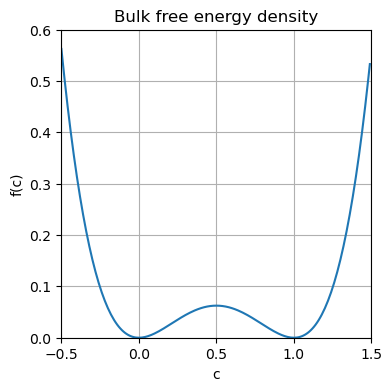

In [6]:
c = np.arange(-0.5, 1.5, 0.01)
f = fbulk(c)

plt.figure(figsize=(4, 4))
plt.plot(c, f, label='f(c)')
plt.xlabel('c')
plt.ylabel('f(c)')
plt.xlim(-0.5, 1.5)
plt.ylim(0.0, 0.6)
plt.grid()
plt.title('Bulk free energy density')

## Defining the `SpectralETD` class

In [7]:
CH = SpectralETD(ndim=2,method='ETD',device='cuda')

Using dimensions: 2
Using method: ETD
Using device: cuda


In [8]:
L = 16*np.pi
Ngrid = 256
CH.Set_Geometry(lengths=L,gridsize=Ngrid)

Defining the Linear Operator

In [9]:
# The linear terms of PDE
def Loperator_k(params):
    M,kappa,K2 = params
    return -M*kappa*K2**2

params = M,kappa,CH.K2
CH.Set_LinearOperator(Loperator_k,params)

Defining the Non-linear Operator

In [10]:
# The non-linear terms of PDE (with dealising)
def Noperator_func(n,params):
    M,W,K2,fft = params
    return -2*M*W*K2*fft(n-3*n**2+2*n**3)

params = M,W,CH.K2,CH.fft
CH.Set_NonLinearOperator(Noperator_func,params)

Setting the timestep

In [11]:
CH.Set_TimeStep(h=0.01)

Using time step: 0.01


## Calculating the Dynamics

In [12]:
T = 2000 # total time

# Setting Initial condition
seed = 12345 # (random seed for reproducibility)
rng = np.random.default_rng(seed)
noise = 0.01
mean = 0.3
n0 = mean + noise*rng.standard_normal((CH.Ngrid[0],CH.Ngrid[1]))  # initial condition
CH.Set_Field(n0) 

# Calculate the dynamics
# ti: initial time, tf: final time, print_every: how often to print progress
# The output is a tuple (t, n) where t is the time array and n is the field array
t, n = CH.Calculate_Dynamics(ti=0.0, tf=T, print_every=1000) 

Step 1000, Time: 10.00
Step 2000, Time: 20.00
Step 3000, Time: 30.00
Step 4000, Time: 40.00
Step 5000, Time: 50.00
Step 6000, Time: 60.00
Step 7000, Time: 70.00
Step 8000, Time: 80.00
Step 9000, Time: 90.00
Step 10000, Time: 100.00
Step 11000, Time: 110.00
Step 12000, Time: 120.00
Step 13000, Time: 130.00
Step 14000, Time: 140.00
Step 15000, Time: 150.00
Step 16000, Time: 160.00
Step 17000, Time: 170.00
Step 18000, Time: 180.00
Step 19000, Time: 190.00
Step 20000, Time: 200.00
Step 21000, Time: 210.00
Step 22000, Time: 220.00
Step 23000, Time: 230.00
Step 24000, Time: 240.00
Step 25000, Time: 250.00
Step 26000, Time: 260.00
Step 27000, Time: 270.00
Step 28000, Time: 280.00
Step 29000, Time: 290.00
Step 30000, Time: 300.00
Step 31000, Time: 310.00
Step 32000, Time: 320.00
Step 33000, Time: 330.00
Step 34000, Time: 340.00
Step 35000, Time: 350.00
Step 36000, Time: 360.00
Step 37000, Time: 370.00
Step 38000, Time: 380.00
Step 39000, Time: 390.00
Step 40000, Time: 400.00
Step 41000, Time: 

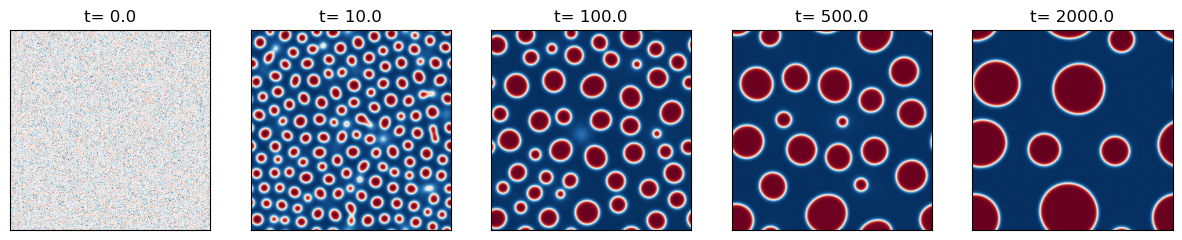

In [16]:
# make a subplot with 5 images
plt.figure(figsize=(15,3))

iprint = np.array([0,1,10,50,-1])

for j in range(iprint.size):
    plt.subplot(1,5,j+1)
    plt.imshow(n[iprint[j]],cmap='RdBu_r')
    plt.title(f"t= {t[iprint[j]]}")
    plt.xticks([])
    plt.yticks([])

# Testing Convergence

In [43]:
print(n[0].mean(),n[-1].mean())

0.30004963 0.30004966


In [44]:
error= np.abs(np.mean(n[0])-np.mean(n,axis=(1,2)))

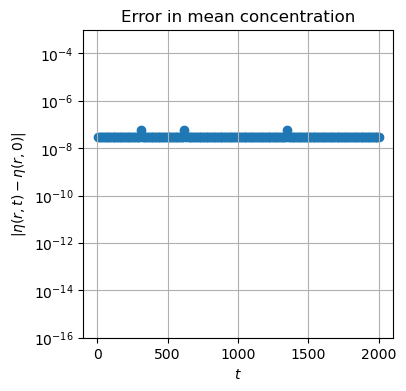

In [52]:
plt.figure(figsize=(4, 4))
plt.title('Error in mean concentration')
plt.yscale('log')
plt.scatter(t,error)
plt.ylim(1e-16,1e-3)
plt.xlabel(r'$t$')
plt.ylabel(r'$|\eta(r,t)-\eta(r,0)|$')
plt.grid()

# Free-energy calculation

In [46]:
def fbulk(c):
    return W*c**2*(1-c)**2

In [47]:
F = np.zeros_like(t)

for i in range(t.size):
    CH.Set_Field(n[i])
    nablacx = CH.ifft(1.0j*CH.Kx*CH.n_k).real.cpu().numpy()
    nablacy = CH.ifft(1.0j*CH.Ky*CH.n_k).real.cpu().numpy()
    nablac2 = nablacx**2+ nablacy**2
    F[i] = np.mean(0.5*kappa*nablac2+fbulk(n[i]))

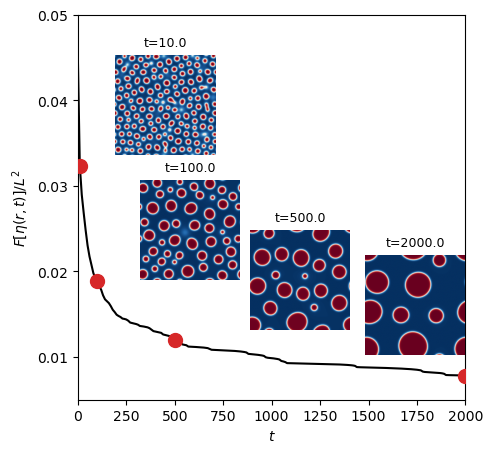

In [48]:
fig, ax1 = plt.subplots(1,1,figsize=(5, 5))
ax1.plot(t,F,'k')
ax1.scatter(t[j1],F[j1],s=100,color='C3',zorder=5)
ax1.scatter(t[j2],F[j2],s=100,color='C3',zorder=5)
ax1.scatter(t[j3],F[j3],s=100,color='C3',zorder=5)
ax1.scatter(t[-1],F[-1],s=100,color='C3',zorder=5)
ax1.set_ylim(0.005,0.05)
ax1.set_xlim(0,T)
ax1.set_xlabel(r'$t$')
ax1.set_ylabel(r'$F[\eta(r,t)]/L^2$')

ax2 = fig.add_axes([0.7, 0.2, 0.2, 0.2])
ax2.imshow(n[-1],cmap='RdBu_r')
ax2.axis('off')
ax2.set_title(fr't={t[-1]:.1f}',fontsize=9)
ax2.set_xticks([])
ax2.set_yticks([])

ax3 = fig.add_axes([0.47, 0.25, 0.2, 0.2])
ax3.imshow(n[j3],cmap='RdBu_r')
ax3.axis('off')
ax3.set_title(fr't={t[j3]:.1f}',fontsize=9)
ax3.set_xticks([])
ax3.set_yticks([])

ax4 = fig.add_axes([0.25, 0.35, 0.2, 0.2])
ax4.imshow(n[j2],cmap='RdBu_r')
ax4.axis('off')
ax4.set_title(fr't={t[j2]:.1f}',fontsize=9)
ax4.set_xticks([])
ax4.set_yticks([])

ax5 = fig.add_axes([0.2, 0.6, 0.2, 0.2])
ax5.imshow(n[j1],cmap='RdBu_r')
ax5.axis('off')
ax5.set_title(fr't={t[j1]:.1f}',fontsize=9)
ax5.set_xticks([])
ax5.set_yticks([])

fig.savefig(f'output/ch2d-c0={mean:.2f}.png', dpi=300, bbox_inches='tight')

# Make a animation

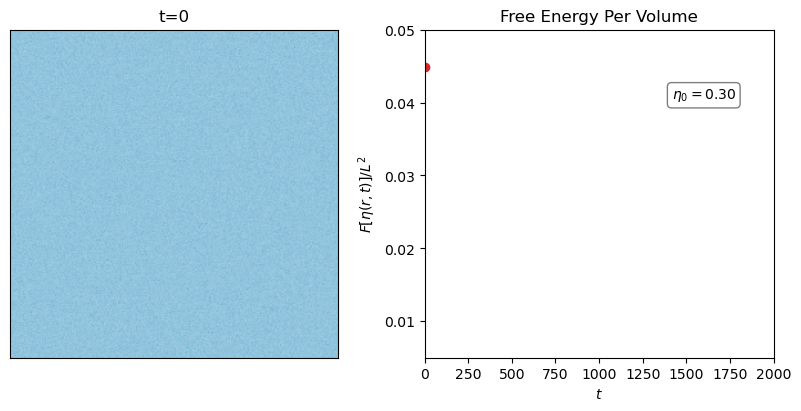

In [49]:
from matplotlib import animation

fig, ax = plt.subplots(1,2,figsize=(8,4), layout='constrained')
#plotting the colormap
im = ax[0].imshow(n[0],cmap='RdBu_r', vmin=0.0, vmax=1.0)
tx = ax[0].set_title(f't={t[0]:.0f}')
ax[0].set_xticks([])
ax[0].set_yticks([])
#plotting the free energy
line, = ax[1].plot(t[0],F[0],color='k')
scat = ax[1].scatter(t[0],F[0],marker='o',color='C3')
ax[1].set_xlabel(r'$t$')
ax[1].set_ylabel(r'$F[\eta(r,t)]/L^2$')
ax[1].set_ylim(0.005,0.05)
ax[1].set_xlim(0,T)
ax[1].set_title('Free Energy Per Volume')
ax[1].text(0.8,0.8,fr'$\eta_0=${mean:.2f}', transform=ax[1].transAxes,ha="center", va="center",fontsize=10,bbox=dict(boxstyle='round', fc='none', ec='k', alpha=0.5))

#function to animate the plot
def animate(i):
    im.set_data(n[i]) # updating data
    im.set_clim(0.0, 1.0)
    tx.set_text(f't={t[i]:.0f}')  

    line.set_data(t[:i],F[:i])
    scat.set_offsets([t[i],F[i]])
    return fig,

ani = animation.FuncAnimation(fig, animate, frames= t.size,interval = 50)
# writervideo = animation.FFMpegWriter(fps=10) 
# ani.save(f'output/ch2d-c0={mean:.2f}-movie.mp4',writer=writervideo,dpi=200)
ani.save(f'output/ch2d-c0={mean:.2f}-movie.gif',writer='pillow',fps=10,dpi=200)